BREAST CANCER WISCONSIN DATASET - EXPLORATORY DATA ANALYSIS

DATASET LOADED SUCCESSFULLY!

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430       

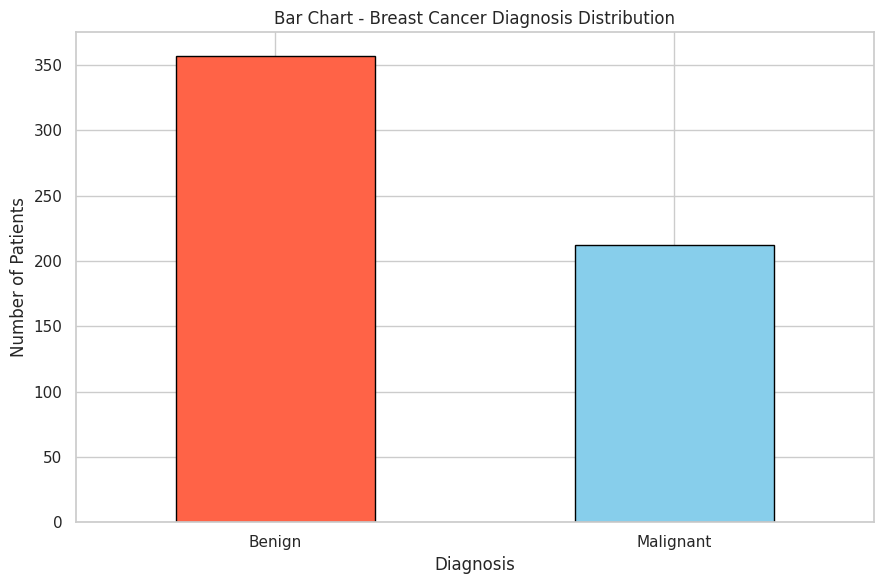

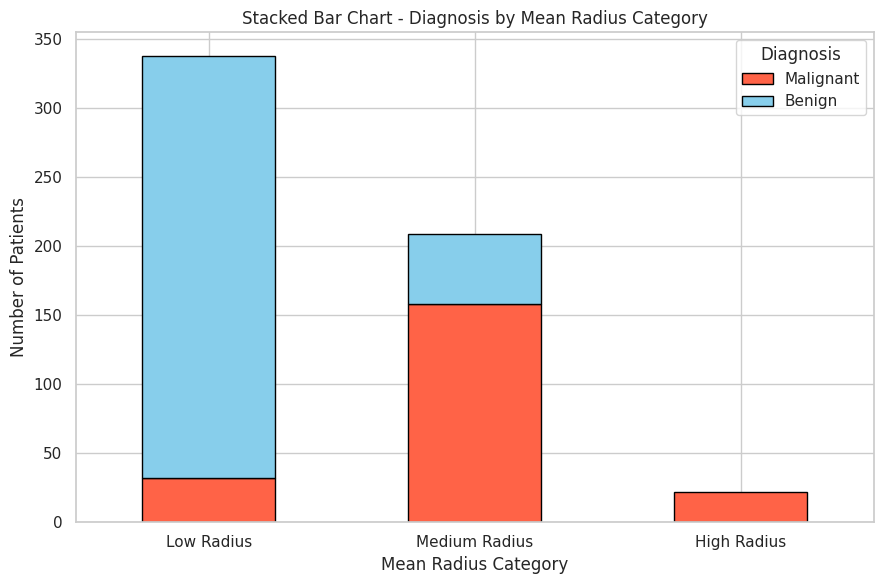

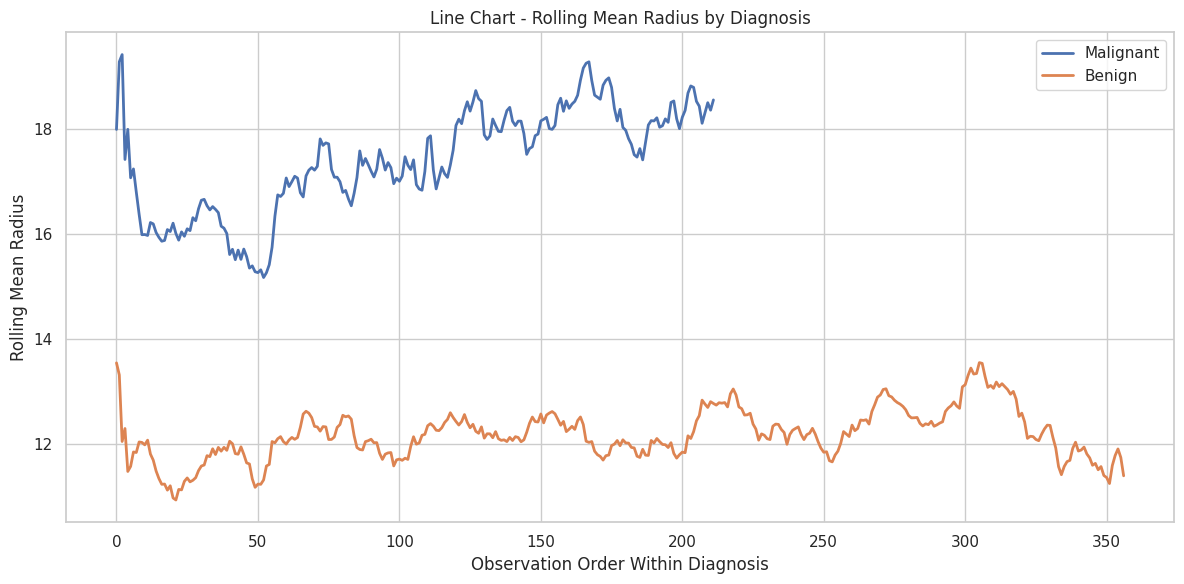

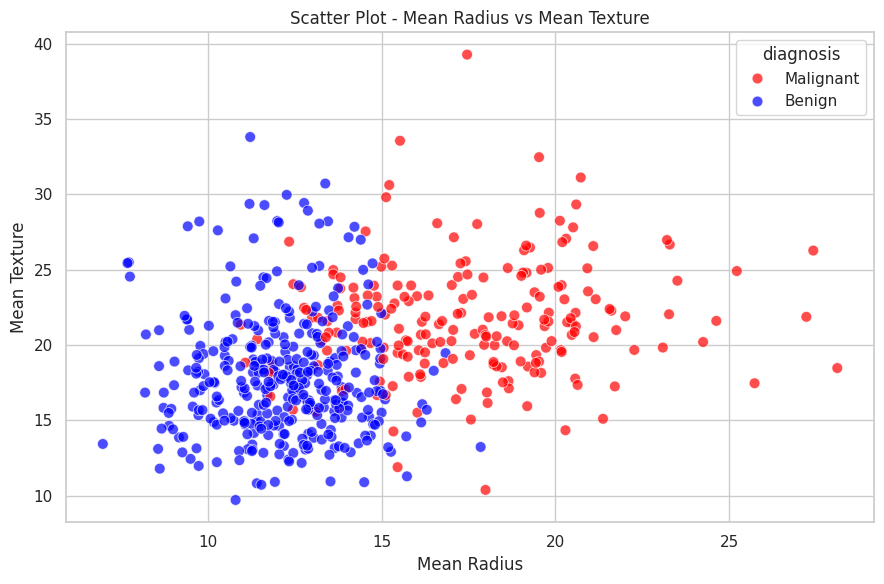

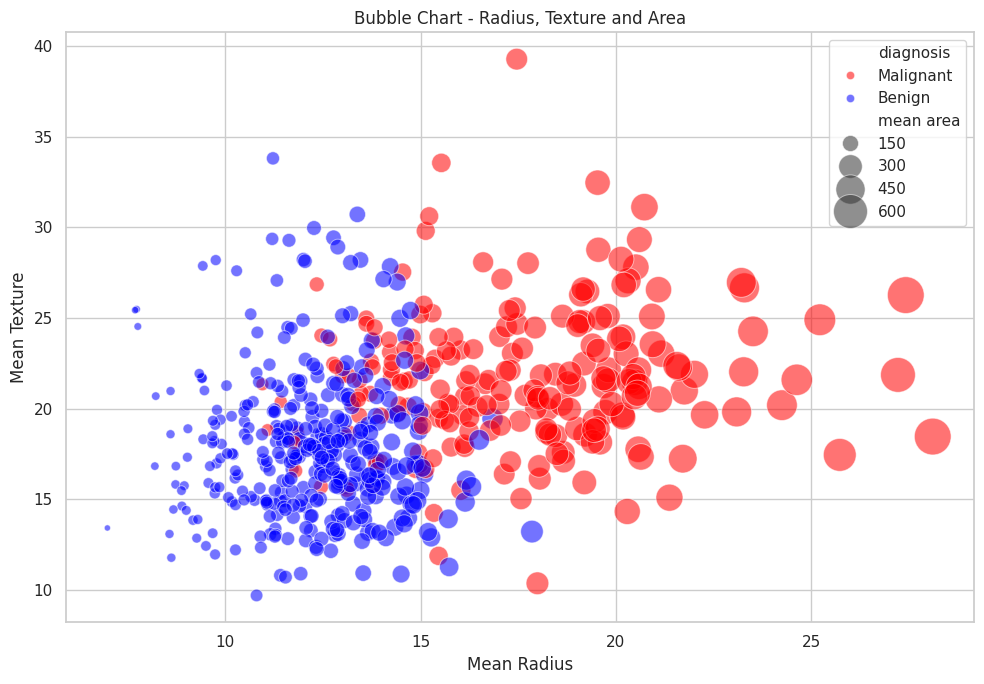

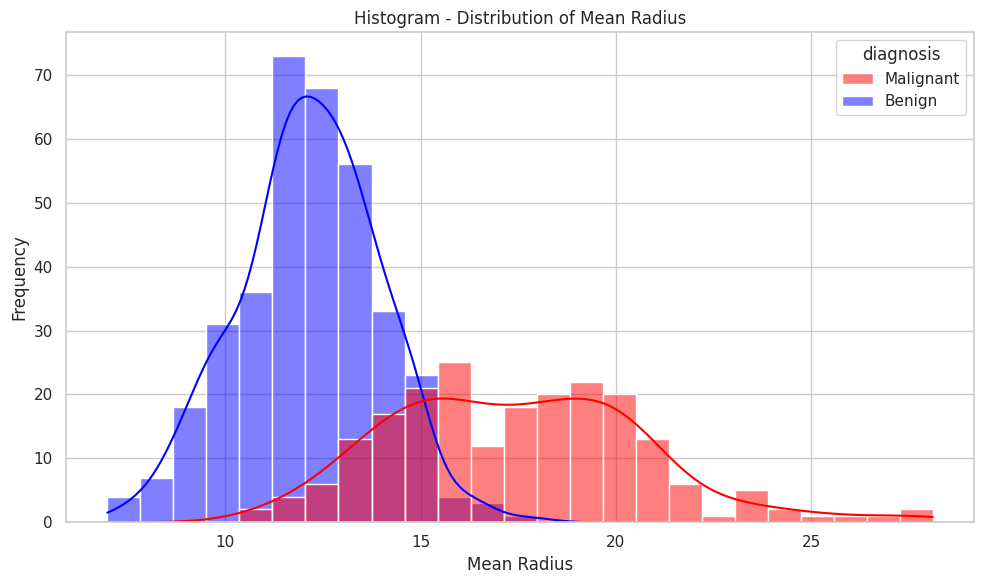

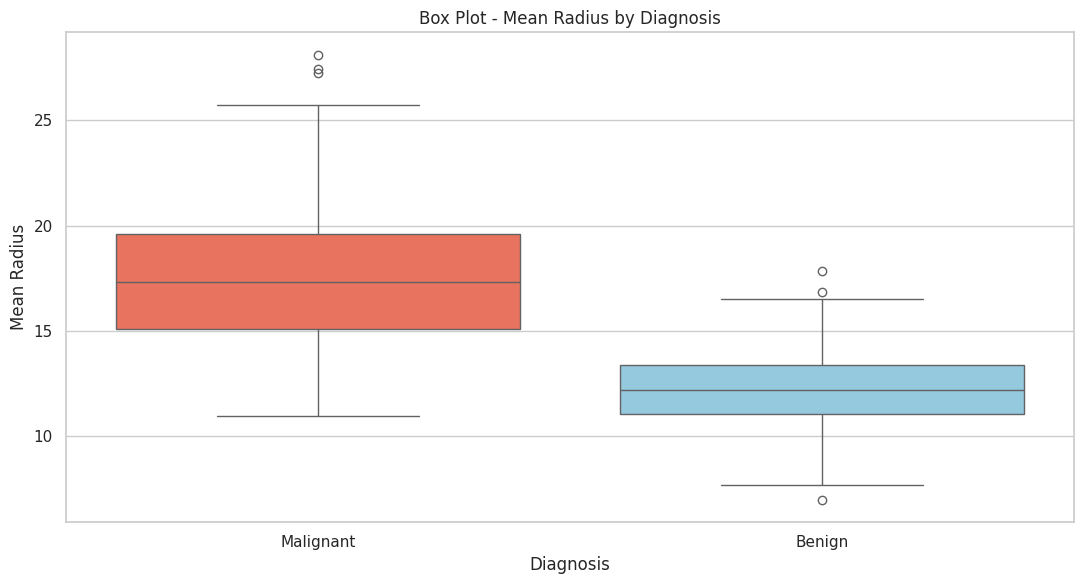

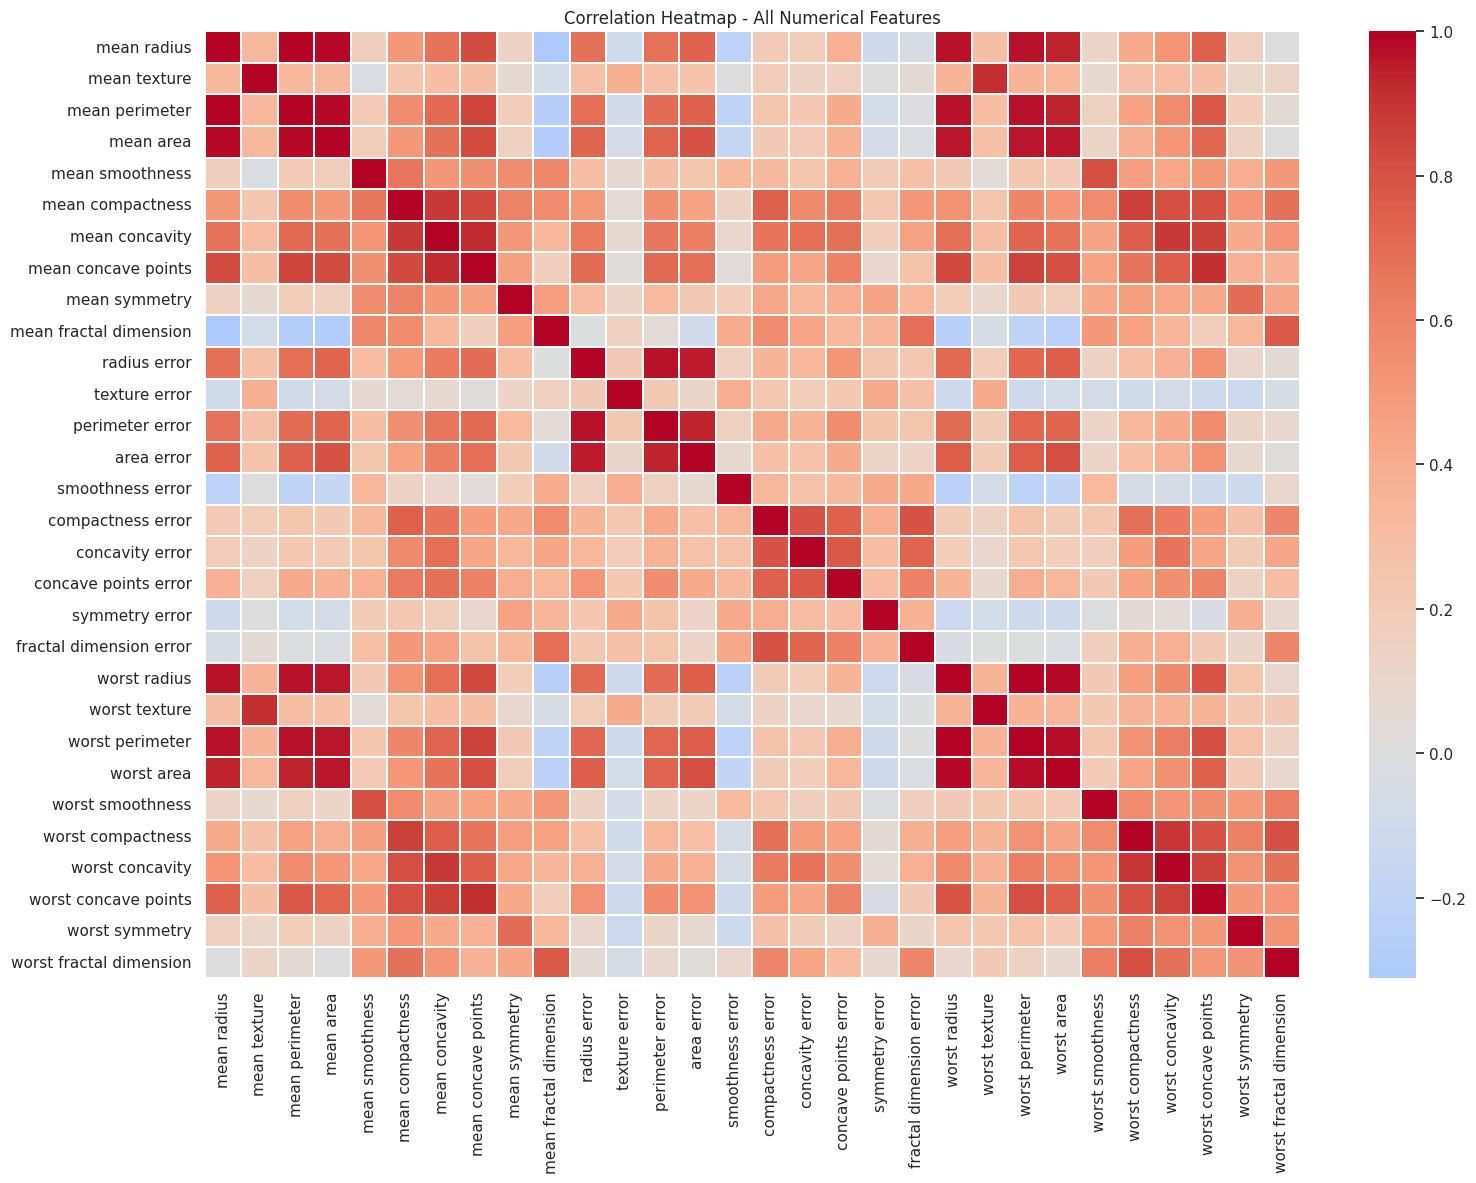

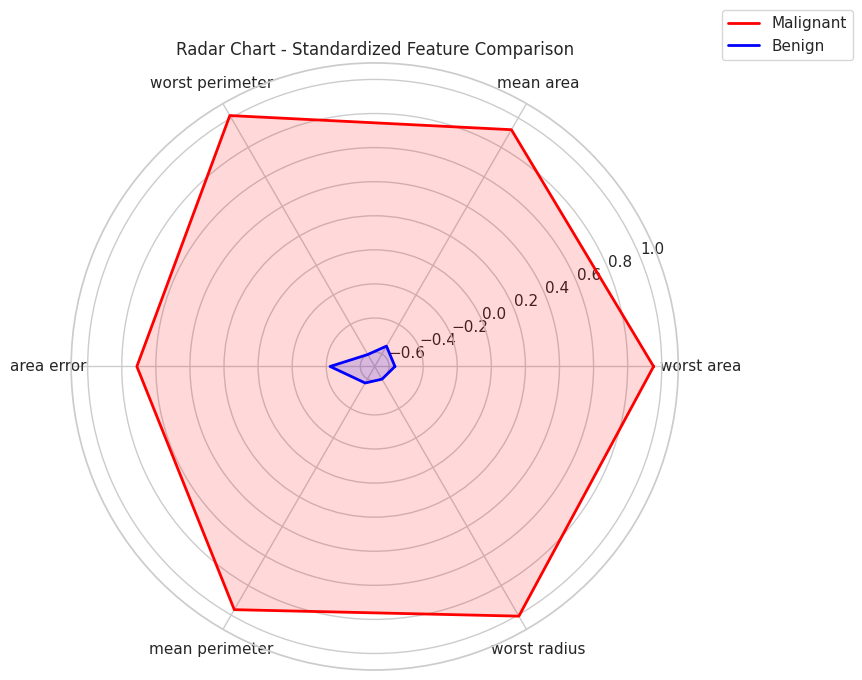

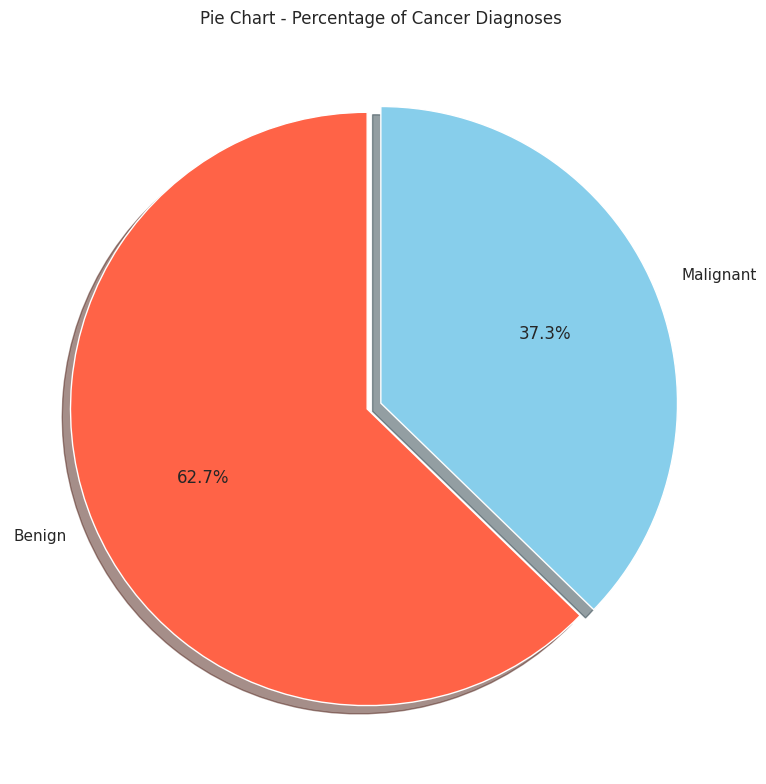

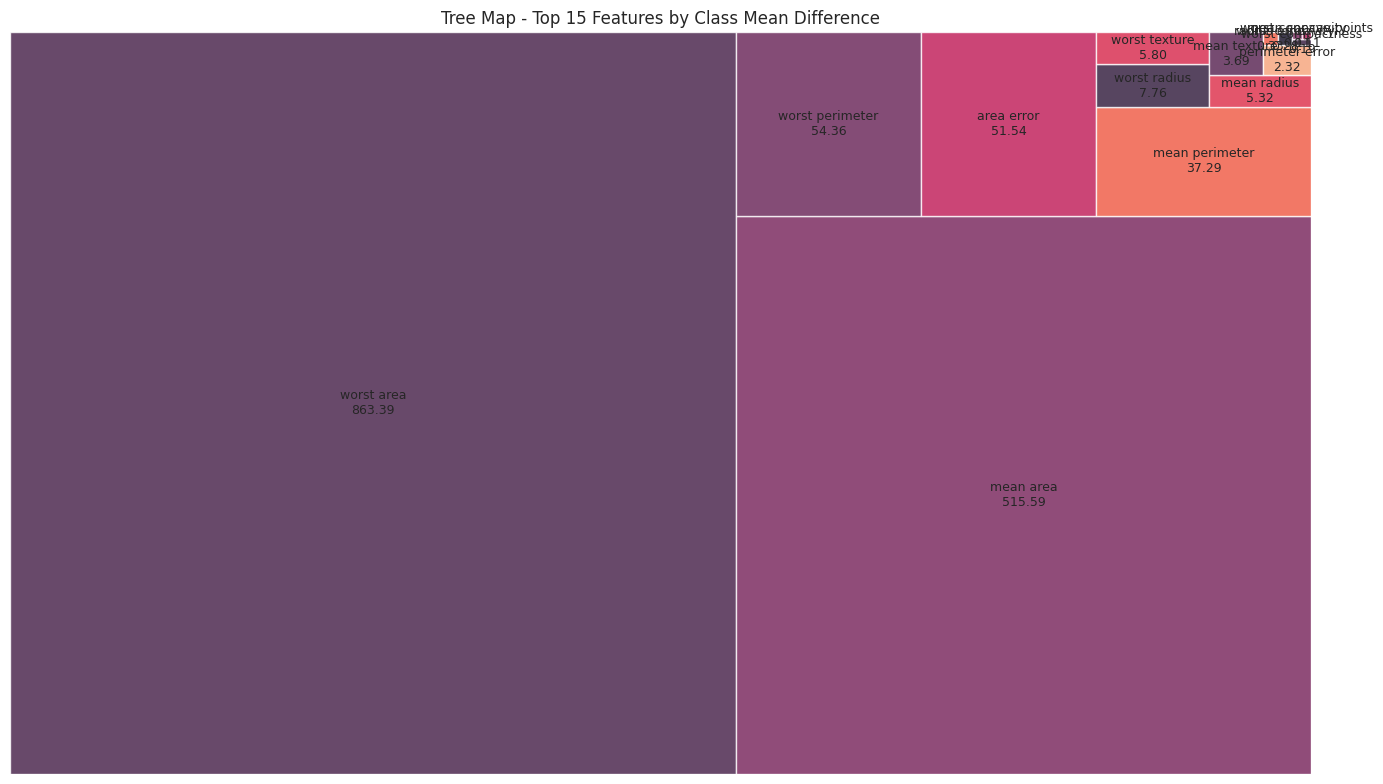

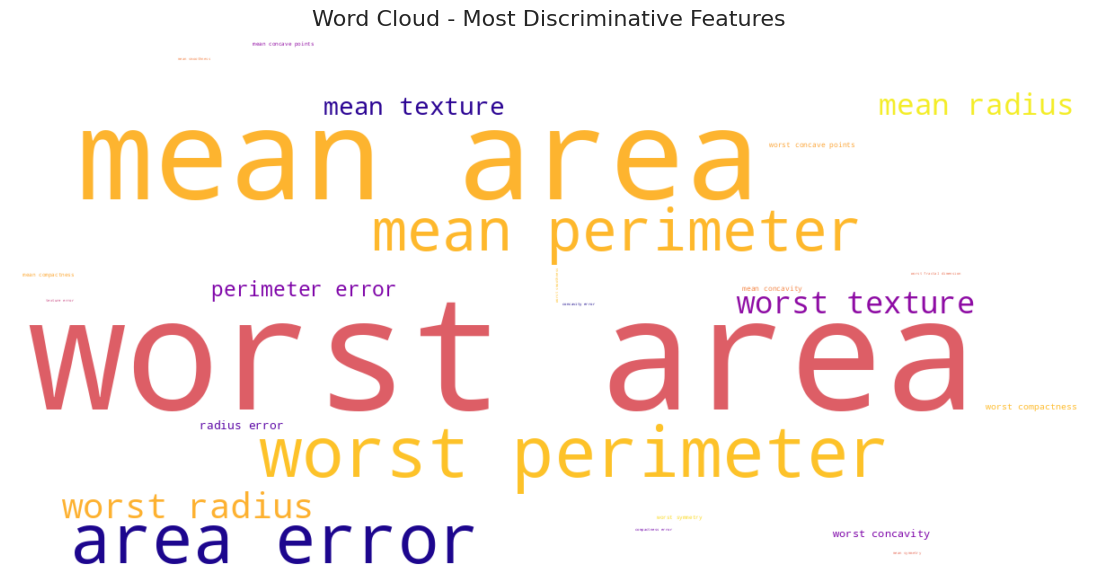


AUTOMATIC EXPLORATORY DATA ANALYSIS - KEY INSIGHTS

1. DATASET OVERVIEW
Total observations: 569
Total numerical features: 30
Malignant cases: 212
Benign cases: 357
Malignant percentage: 37.26 %
Benign percentage: 62.74 %

2. MISSING VALUE ANALYSIS
No missing values found.

3. FEATURE DISTRIBUTION
Average mean radius: 14.13
Average mean texture: 19.29
Average mean area: 654.89

4. CLASS-WISE FEATURE COMPARISON
diagnosis         Malignant  Benign
mean radius           17.46   12.15
mean texture          21.60   17.91
mean perimeter       115.37   78.08
mean area            978.38  462.79
mean smoothness        0.10    0.09
mean compactness       0.15    0.08

Features with higher mean values in malignant cases:
- mean radius
- mean texture
- mean perimeter
- mean area
- mean smoothness
- mean compactness

5. TOP 10 MOST DISCRIMINATIVE FEATURES
worst area         863.387
mean area          515.586
worst perimeter     54.364
area error          51.537
mean perimeter      37.290
worst radi

In [ ]:
####### LAB PROGARM 2


!pip install -q wordcloud squarify

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from wordcloud import WordCloud
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("=" * 70)
print("BREAST CANCER WISCONSIN DATASET - EXPLORATORY DATA ANALYSIS")
print("=" * 70)




data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

# Convert target into readable labels
df['diagnosis'] = pd.Categorical(
    np.where(data.target == 0, 'Malignant', 'Benign'),
    categories=['Malignant', 'Benign']
)

print("\nDATASET LOADED SUCCESSFULLY!")
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDiagnosis Distribution:")
print(df['diagnosis'].value_counts())




features = list(data.feature_names)

# Select important features for visualization
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean compactness'
]

# Diagnosis counts
diagnosis_counts = df['diagnosis'].value_counts()

# Mean feature values by diagnosis
class_means = df.groupby('diagnosis', observed=False)[features].mean()




plt.figure(figsize=(9, 6))

diagnosis_counts.plot(
    kind='bar',
    color=['tomato', 'skyblue'],
    edgecolor='black'
)

plt.title("Bar Chart - Breast Cancer Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




df['radius_category'] = pd.cut(
    df['mean radius'],
    bins=3,
    labels=['Low Radius', 'Medium Radius', 'High Radius']
)

stacked_data = pd.crosstab(
    df['radius_category'],
    df['diagnosis']
)

stacked_data.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6),
    color=['tomato', 'skyblue'],
    edgecolor='black'
)

plt.title("Stacked Bar Chart - Diagnosis by Mean Radius Category")
plt.xlabel("Mean Radius Category")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()




plt.figure(figsize=(12, 6))

for diagnosis in ['Malignant', 'Benign']:

    subset = df[df['diagnosis'] == diagnosis]

    rolling_mean = subset['mean radius'].reset_index(
        drop=True
    ).rolling(window=20, min_periods=1).mean()

    plt.plot(
        rolling_mean,
        label=diagnosis,
        linewidth=2
    )

plt.title("Line Chart - Rolling Mean Radius by Diagnosis")
plt.xlabel("Observation Order Within Diagnosis")
plt.ylabel("Rolling Mean Radius")
plt.legend()
plt.tight_layout()
plt.show()




plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='mean radius',
    y='mean texture',
    hue='diagnosis',
    palette={
        'Malignant': 'red',
        'Benign': 'blue'
    },
    alpha=0.7,
    s=60
)

plt.title("Scatter Plot - Mean Radius vs Mean Texture")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.tight_layout()
plt.show()



plt.figure(figsize=(10, 7))

bubble_sizes = (
    df['mean area'] /
    df['mean area'].max()
) * 700

sns.scatterplot(
    data=df,
    x='mean radius',
    y='mean texture',
    hue='diagnosis',
    size=bubble_sizes,
    sizes=(20, 700),
    alpha=0.55,
    palette={
        'Malignant': 'red',
        'Benign': 'blue'
    },
    legend='brief'
)

plt.title("Bubble Chart - Radius, Texture and Area")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.tight_layout()
plt.show()




plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='mean radius',
    hue='diagnosis',
    kde=True,
    bins=25,
    palette={
        'Malignant': 'red',
        'Benign': 'blue'
    },
    alpha=0.5
)

plt.title("Histogram - Distribution of Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='diagnosis',
    y='mean radius',
    hue='diagnosis',
    palette={
        'Malignant': 'tomato',
        'Benign': 'skyblue'
    },
    legend=False
)

plt.title("Box Plot - Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.tight_layout()
plt.show()



correlation_matrix = df[features].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.2,
    cbar=True
)

plt.title("Correlation Heatmap - All Numerical Features")
plt.tight_layout()
plt.show()



# Select six important features using class separation
effect_scores = (
    class_means.loc['Malignant'] -
    class_means.loc['Benign']
).abs()

radar_features = effect_scores.nlargest(6).index.tolist()

# Standardize features to make different scales comparable
scaler = StandardScaler()

scaled_values = scaler.fit_transform(df[radar_features])

scaled_df = pd.DataFrame(
    scaled_values,
    columns=radar_features
)

scaled_df['diagnosis'] = df['diagnosis'].values

radar_means = scaled_df.groupby('diagnosis')[radar_features].mean()

angles = np.linspace(
    0,
    2 * np.pi,
    len(radar_features),
    endpoint=False
).tolist()

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(9, 9),
    subplot_kw={'polar': True}
)

for diagnosis, color in [
    ('Malignant', 'red'),
    ('Benign', 'blue')
]:

    values = radar_means.loc[diagnosis].tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=diagnosis,
        color=color
    )

    ax.fill(
        angles,
        values,
        alpha=0.15,
        color=color
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features)

ax.set_title("Radar Chart - Standardized Feature Comparison")
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()



plt.figure(figsize=(8, 8))

plt.pie(
    diagnosis_counts,
    labels=diagnosis_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['tomato', 'skyblue'],
    explode=(0.05, 0),
    shadow=True
)

plt.title("Pie Chart - Percentage of Cancer Diagnoses")
plt.tight_layout()
plt.show()



# Calculate absolute standardized difference between classes
treemap_data = effect_scores.sort_values(
    ascending=False
).head(15)

plt.figure(figsize=(14, 8))

squarify.plot(
    sizes=treemap_data.values,
    label=[
        f"{name}\n{value:.2f}"
        for name, value in treemap_data.items()
    ],
    alpha=0.8,
    text_kwargs={'fontsize': 9}
)

plt.title("Tree Map - Top 15 Features by Class Mean Difference")
plt.axis('off')
plt.tight_layout()
plt.show()


# Word size represents the difference between class means
word_frequencies = {
    feature: float(score)
    for feature, score in effect_scores.items()
}

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='plasma',
    max_words=40
).generate_from_frequencies(word_frequencies)

plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title(
    "Word Cloud - Most Discriminative Features",
    fontsize=16
)

plt.show()




print("\n" + "=" * 70)
print("AUTOMATIC EXPLORATORY DATA ANALYSIS - KEY INSIGHTS")
print("=" * 70)


# A. Dataset overview

print("\n1. DATASET OVERVIEW")

print("Total observations:", len(df))
print("Total numerical features:", len(features))
print("Malignant cases:", diagnosis_counts['Malignant'])
print("Benign cases:", diagnosis_counts['Benign'])

print(
    "Malignant percentage:",
    round(
        diagnosis_counts['Malignant'] / len(df) * 100,
        2
    ),
    "%"
)

print(
    "Benign percentage:",
    round(
        diagnosis_counts['Benign'] / len(df) * 100,
        2
    ),
    "%"
)


# B. Missing values

print("\n2. MISSING VALUE ANALYSIS")

missing = df[features].isnull().sum().sum()

if missing == 0:
    print("No missing values found.")
else:
    print("Missing values detected:", missing)


# C. Feature distribution

print("\n3. FEATURE DISTRIBUTION")

print(
    "Average mean radius:",
    round(df['mean radius'].mean(), 2)
)

print(
    "Average mean texture:",
    round(df['mean texture'].mean(), 2)
)

print(
    "Average mean area:",
    round(df['mean area'].mean(), 2)
)


# D. Class-wise feature comparison

print("\n4. CLASS-WISE FEATURE COMPARISON")

comparison = df.groupby(
    'diagnosis',
    observed=False
)[selected_features].mean().T

print(comparison.round(2))

print(
    "\nFeatures with higher mean values in malignant cases:"
)

for feature in selected_features:

    if (
        class_means.loc['Malignant', feature] >
        class_means.loc['Benign', feature]
    ):

        print("-", feature)


# E. Important features

print("\n5. TOP 10 MOST DISCRIMINATIVE FEATURES")

print(
    effect_scores.sort_values(
        ascending=False
    ).head(10).round(3)
)


# F. Correlation analysis

print("\n6. HIGHLY CORRELATED FEATURE PAIRS")

corr_pairs = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
).stack()

print(
    corr_pairs.reindex(
        corr_pairs.abs().sort_values(
            ascending=False
        ).index
    ).head(10).round(3)
)


# G. Outlier detection using IQR

print("\n7. OUTLIER DETECTION USING IQR METHOD")

outlier_counts = {}

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_counts[feature] = len(outliers)

outlier_series = pd.Series(
    outlier_counts
).sort_values(ascending=False)

print("Top 10 features with the most IQR outliers:")

print(outlier_series.head(10))

print(
    "\nTotal feature-level outlier observations:",
    sum(outlier_counts.values())
)

print(
    "Note: The same observation may be an outlier in multiple features."
)


# H. Relationship between radius and area

print("\n8. FEATURE RELATIONSHIP ANALYSIS")

radius_area_corr = df[
    ['mean radius', 'mean area']
].corr().iloc[0, 1]

print(
    "Correlation between mean radius and mean area:",
    round(radius_area_corr, 3)
)

if radius_area_corr > 0.7:
    print("Strong positive relationship detected.")
elif radius_area_corr < -0.7:
    print("Strong negative relationship detected.")
else:
    print("Weak or moderate linear relationship detected.")


# I. Overall interpretation

print("\n9. FINAL DATASET INSIGHTS")

print("""
1. The dataset contains measurements extracted from digitized
   images of breast mass samples.

2. The target variable classifies observations as malignant
   or benign.

3. The bar chart and pie chart show the distribution of
   malignant and benign cases.

4. The stacked bar chart compares diagnosis categories across
   different mean-radius groups.

5. The line chart shows rolling mean radius patterns in the
   dataset's observation order. It does not represent time.

6. The scatter and bubble charts help identify relationships
   between radius, texture and area.

7. The histogram displays the distribution and possible skewness
   of mean radius.

8. The box plot helps identify differences in median values,
   spread and potential outliers between diagnosis groups.

9. The correlation heatmap reveals strongly related numerical
   features and possible multicollinearity.

10. The radar chart compares standardized feature patterns
    between malignant and benign observations.

11. The treemap and word cloud highlight features with large
    differences in average measurements between the two classes.

12. IQR outliers are statistical extremes and are not necessarily
    measurement errors or abnormal patients.

13. These visualizations are exploratory. They do not establish
    causation or provide a clinical diagnosis.
""")

print("=" * 70)
print("EDA COMPLETED SUCCESSFULLY!")
print("=" * 70)
